# TP2 - Deep Q-Network

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
import torch
import os   

from q_learning import *
from envs import *

from dqn import *

## Parte 1 - Q-Learning: FrozenLake-v1

In [2]:
env = gym.make(
    "FrozenLake-v1",
    map_name="4x4",
    is_slippery=True,
)

print("Observation space:", env.observation_space)
print("Action space:", env.action_space)
print("Reward threshold:", env.spec.reward_threshold)

Observation space: Discrete(16)
Action space: Discrete(4)
Reward threshold: 0.7


In [3]:
q_table, history = train_q_learning(
    env,
    num_episodes=20000,
    alpha=0.1,
    gamma=0.99,
    epsilon_max=1.0,
    epsilon_min=0.05,
    decay=0.0002,
    seed=42,
)

print("Q-table:")
print(np.round(q_table, 3))

print("Training time:", history["wall_time"])
print("Last 1000 episodes mean reward:",
      np.mean(history["rewards"][-1000:]))

Q-table:
[[0.537 0.52  0.534 0.527]
 [0.367 0.3   0.254 0.517]
 [0.431 0.43  0.4   0.48 ]
 [0.289 0.332 0.256 0.457]
 [0.548 0.328 0.448 0.211]
 [0.    0.    0.    0.   ]
 [0.238 0.203 0.379 0.034]
 [0.    0.    0.    0.   ]
 [0.455 0.417 0.324 0.605]
 [0.496 0.649 0.305 0.357]
 [0.699 0.418 0.311 0.398]
 [0.    0.    0.    0.   ]
 [0.    0.    0.    0.   ]
 [0.485 0.565 0.769 0.436]
 [0.759 0.894 0.806 0.767]
 [0.    0.    0.    0.   ]]
Training time: 11.132545800006483
Last 1000 episodes mean reward: 0.467


In [4]:
eval_env = gym.make(
    "FrozenLake-v1",
    map_name="4x4",
    is_slippery=True,
)

greedy_results = evaluate_q_learning(
    eval_env,
    q_table,
    num_episodes=100,
    epsilon=0.0,
    seed=1234,
)

exploration_results = evaluate_q_learning(
    eval_env,
    q_table,
    num_episodes=100,
    epsilon=0.1,
    seed=1234,
)

print(
    "Success rate (epsilon=0):",
    greedy_results["success_rate"],
    "%"
)

print(
    "Success rate (epsilon=0.1):",
    exploration_results["success_rate"],
    "%"
)

Success rate (epsilon=0): 78.0 %
Success rate (epsilon=0.1): 38.0 %


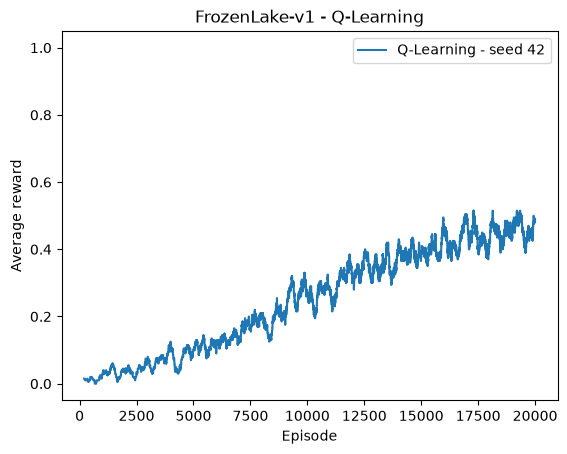

In [5]:
rewards = history["rewards"]

window = 200

moving_average = np.convolve(
    rewards,
    np.ones(window) / window,
    mode="valid"
)

plt.plot(
    np.arange(window - 1, len(rewards)),
    moving_average,
    label="Q-Learning - seed 42"
)

plt.xlabel("Episode")
plt.ylabel("Average reward")
plt.title("FrozenLake-v1 - Q-Learning")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.show()

In [6]:
os.makedirs("results/experiments", exist_ok=True)

np.savez(
    "results/experiments/frozenlake_seed42.npz",
    q_table=q_table,
    rewards=history["rewards"],
    lengths=history["lengths"],
    epsilons=history["epsilons"],
    wall_time=history["wall_time"],
)

print("Results saved.")

Results saved.


### Comparación entre semillas

In [7]:
seeds = [42, 123, 456]

all_rewards = []
results = []

os.makedirs("results/experiments", exist_ok=True)

for seed in seeds:
    train_env = gym.make(
        "FrozenLake-v1",
        map_name="4x4",
        is_slippery=True
    )

    q, hist = train_q_learning(
        train_env,
        num_episodes=20000,
        alpha=0.1,
        gamma=0.99,
        epsilon_max=1.0,
        epsilon_min=0.05,
        decay=0.0002,
        seed=seed
    )

    eval_env = gym.make(
        "FrozenLake-v1",
        map_name="4x4",
        is_slippery=True
    )

    greedy = evaluate_q_learning(
        eval_env,
        q,
        num_episodes=100,
        epsilon=0.0,
        seed=1000
    )

    exploratory = evaluate_q_learning(
        eval_env,
        q,
        num_episodes=100,
        epsilon=0.1,
        seed=1000
    )

    all_rewards.append(hist["rewards"])

    results.append({
        "seed": seed,
        "greedy_success": greedy["success_rate"],
        "exploratory_success": exploratory["success_rate"],
        "wall_time": hist["wall_time"]
    })

    np.savez(
        f"results/experiments/frozenlake_seed{seed}.npz",
        q_table=q,
        rewards=hist["rewards"],
        lengths=hist["lengths"],
        epsilons=hist["epsilons"],
        wall_time=hist["wall_time"],
        greedy_success=greedy["success_rate"],
        exploratory_success=exploratory["success_rate"]
    )

    train_env.close()
    eval_env.close()

for result in results:
    print(result)

{'seed': 42, 'greedy_success': np.float64(62.0), 'exploratory_success': np.float64(44.0), 'wall_time': 11.524022700003115}
{'seed': 123, 'greedy_success': np.float64(62.0), 'exploratory_success': np.float64(44.0), 'wall_time': 10.451305399998091}
{'seed': 456, 'greedy_success': np.float64(63.0), 'exploratory_success': np.float64(38.0), 'wall_time': 10.385092700016685}


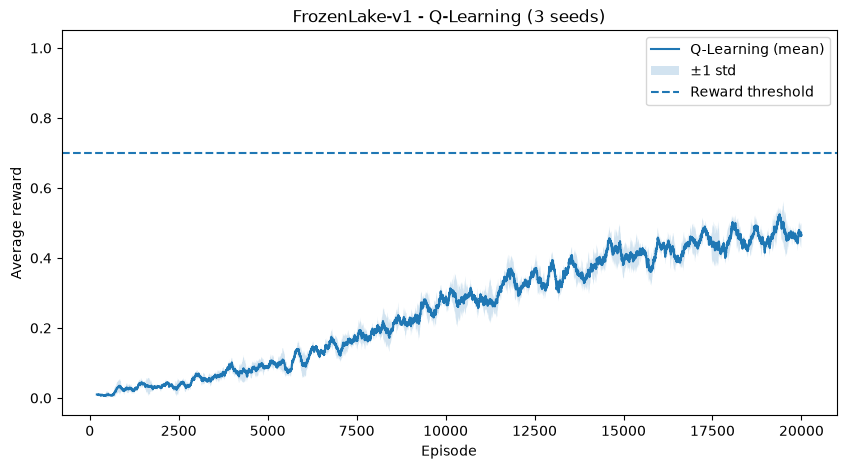

In [8]:
all_rewards = np.array(all_rewards)

window = 200
kernel = np.ones(window) / window

smoothed_rewards = np.array([
    np.convolve(rewards, kernel, mode="valid")
    for rewards in all_rewards
])

mean_reward = smoothed_rewards.mean(axis=0)
std_reward = smoothed_rewards.std(axis=0)

episodes = np.arange(
    window - 1,
    len(all_rewards[0])
)

plt.figure(figsize=(10, 5))

plt.plot(
    episodes,
    mean_reward,
    label="Q-Learning (mean)"
)

plt.fill_between(
    episodes,
    mean_reward - std_reward,
    mean_reward + std_reward,
    alpha=0.2,
    label="±1 std"
)

plt.axhline(
    0.7,
    linestyle="--",
    label="Reward threshold"
)

plt.xlabel("Episode")
plt.ylabel("Average reward")
plt.title("FrozenLake-v1 - Q-Learning (3 seeds)")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.show()

In [9]:
seeds = [42, 123, 456]

for seed in seeds:
    data = np.load(
        f"results/experiments/frozenlake_seed{seed}.npz"
    )

    q_table = data["q_table"]

    eval_env = gym.make(
        "FrozenLake-v1",
        map_name="4x4",
        is_slippery=True
    )

    greedy = evaluate_q_learning(
        eval_env,
        q_table,
        num_episodes=1000,
        epsilon=0.0,
        seed=1000
    )

    exploratory = evaluate_q_learning(
        eval_env,
        q_table,
        num_episodes=1000,
        epsilon=0.1,
        seed=1000
    )

    print(
        f"Seed {seed}: "
        f"greedy={greedy['success_rate']:.1f}% | "
        f"epsilon=0.1: {exploratory['success_rate']:.1f}%"
    )

    eval_env.close()

Seed 42: greedy=72.7% | epsilon=0.1: 41.2%
Seed 123: greedy=72.7% | epsilon=0.1: 41.2%
Seed 456: greedy=72.7% | epsilon=0.1: 38.0%


### Comparación de hiperparámetros

In [10]:
seeds = [42, 123, 456]

slow_decay_rewards = []
slow_decay_results = []

for seed in seeds:
    train_env = gym.make(
        "FrozenLake-v1",
        map_name="4x4",
        is_slippery=True
    )

    q, hist = train_q_learning(
        train_env,
        num_episodes=20000,
        alpha=0.1,
        gamma=0.99,
        epsilon_max=1.0,
        epsilon_min=0.05,
        decay=0.0001,
        seed=seed
    )

    eval_env = gym.make(
        "FrozenLake-v1",
        map_name="4x4",
        is_slippery=True
    )

    greedy = evaluate_q_learning(
        eval_env, q,
        num_episodes=100,
        epsilon=0.0,
        seed=1000
    )

    exploratory = evaluate_q_learning(
        eval_env, q,
        num_episodes=100,
        epsilon=0.1,
        seed=1000
    )

    slow_decay_rewards.append(hist["rewards"])

    slow_decay_results.append({
        "seed": seed,
        "greedy_success": greedy["success_rate"],
        "exploratory_success": exploratory["success_rate"]
    })

    np.savez(
        f"results/experiments/frozenlake_slow_decay_seed{seed}.npz",
        q_table=q,
        rewards=hist["rewards"],
        lengths=hist["lengths"],
        epsilons=hist["epsilons"],
        greedy_success=greedy["success_rate"],
        exploratory_success=exploratory["success_rate"],
        wall_time=hist["wall_time"]
    )

    train_env.close()
    eval_env.close()

for result in slow_decay_results:
    print(result)

{'seed': 42, 'greedy_success': np.float64(62.0), 'exploratory_success': np.float64(44.0)}
{'seed': 123, 'greedy_success': np.float64(63.0), 'exploratory_success': np.float64(38.0)}
{'seed': 456, 'greedy_success': np.float64(59.0), 'exploratory_success': np.float64(28.000000000000004)}


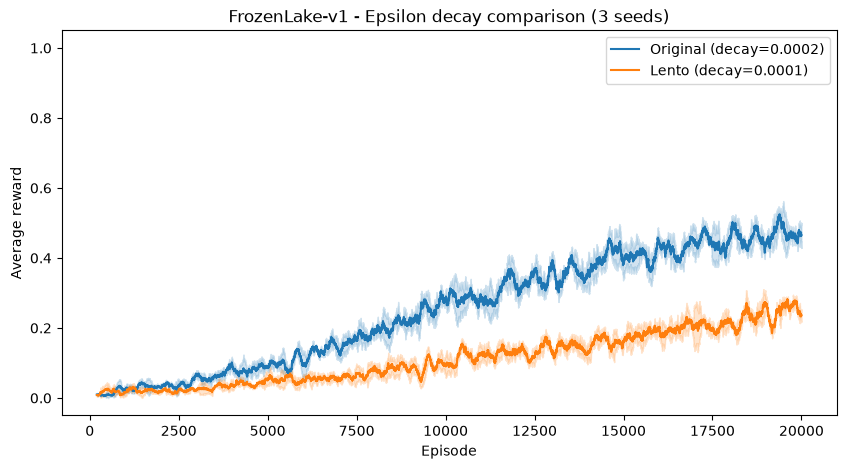

In [11]:
seeds = [42, 123, 456]
window = 200
kernel = np.ones(window) / window

plt.figure(figsize=(10, 5))

configs = [
    ("Original (decay=0.0002)", "frozenlake_seed"),
    ("Lento (decay=0.0001)", "frozenlake_slow_decay_seed")
]

for label, prefix in configs:
    runs = []

    for seed in seeds:
        data = np.load(
            f"results/experiments/{prefix}{seed}.npz"
        )
        smoothed = np.convolve(
            data["rewards"], kernel, mode="valid"
        )
        runs.append(smoothed)

    runs = np.array(runs)

    mean = runs.mean(axis=0)
    std = runs.std(axis=0)
    episodes = np.arange(window - 1, window - 1 + len(mean))

    line, = plt.plot(episodes, mean, label=label)

    plt.fill_between(
        episodes,
        mean - std,
        mean + std,
        alpha=0.2,
        color=line.get_color()
    )

plt.xlabel("Episode")
plt.ylabel("Average reward")
plt.title("FrozenLake-v1 - Epsilon decay comparison (3 seeds)")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.show()

### Política greedy aprendida

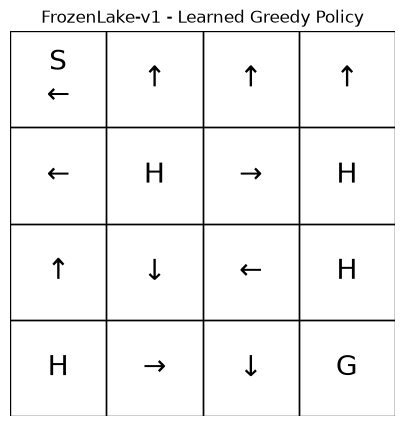

In [12]:
os.makedirs("results/figures", exist_ok=True)

data = np.load(
    "results/experiments/frozenlake_seed42.npz"
)

q_table_best = data["q_table"]

env_map = gym.make(
    "FrozenLake-v1",
    map_name="4x4",
    is_slippery=True
)

desc = env_map.unwrapped.desc

arrows = {
    0: "←",
    1: "↓",
    2: "→",
    3: "↑"
}

fig, ax = plt.subplots(figsize=(5, 5))

for row in range(4):
    for col in range(4):

        state = row * 4 + col
        cell = desc[row, col].decode("utf-8")

        best_action = np.argmax(q_table_best[state])

        if cell == "H":
            symbol = "H"
        elif cell == "G":
            symbol = "G"
        elif cell == "S":
            symbol = f"S\n{arrows[best_action]}"
        else:
            symbol = arrows[best_action]

        rect = plt.Rectangle(
            (col, row),
            1, 1,
            fill=False,
            edgecolor="black"
        )

        ax.add_patch(rect)

        ax.text(
            col + 0.5,
            row + 0.5,
            symbol,
            ha="center",
            va="center",
            fontsize=20
        )

ax.set_xlim(0, 4)
ax.set_ylim(4, 0)
ax.set_aspect("equal")
ax.axis("off")

plt.title("FrozenLake-v1 - Learned Greedy Policy")

plt.savefig(
    "results/figures/frozenlake_greedy_policy.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

env_map.close()

In [13]:
def run_greedy_episode(env, q_table, seed):
    state, _ = env.reset(seed=seed)

    terminated = False
    truncated = False

    total_reward = 0.0
    steps = 0

    trajectory = [state]

    while not (terminated or truncated):
        action = int(np.argmax(q_table[state]))
        state, reward, terminated, truncated, _ = env.step(action)

        trajectory.append(state)
        total_reward += reward
        steps += 1

    return {
        "total_reward": total_reward,
        "steps": steps,
        "success": total_reward > 0,
        "trajectory": trajectory,
    }

In [14]:
video_search_env = gym.make(
    "FrozenLake-v1",
    map_name="4x4",
    is_slippery=True
)

successful_seed = None

for test_seed in range(1000, 1100):
    result = run_greedy_episode(
        video_search_env,
        q_table_best,
        seed=test_seed
    )

    if result["success"]:
        successful_seed = test_seed
        print("Successful seed found:", successful_seed)
        print("Steps:", result["steps"])
        print("Trajectory:", result["trajectory"])
        break

video_search_env.close()

if successful_seed is None:
    print("No successful seed found in searched range.")

Successful seed found: 1001
Steps: 17
Trajectory: [0, 0, 0, 4, 0, 0, 0, 0, 0, 0, 0, 4, 8, 9, 13, 13, 14, 15]


In [15]:
os.makedirs("results/videos", exist_ok=True)

video_env = gym.make(
    "FrozenLake-v1",
    map_name="4x4",
    is_slippery=True,
    render_mode="rgb_array"
)

video_env = gym.wrappers.RecordVideo(
    video_env,
    video_folder="results/videos/frozenlake",
    name_prefix="frozenlake_greedy",
    episode_trigger=lambda episode_id: True,
)

state, _ = video_env.reset(seed=successful_seed)

terminated = False
truncated = False
total_reward = 0.0
steps = 0

while not (terminated or truncated):
    action = int(np.argmax(q_table_best[state]))
    state, reward, terminated, truncated, _ = video_env.step(action)
    total_reward += reward
    steps += 1

video_env.close()

print("Total reward:", total_reward)
print("Episode length:", steps)
print("Terminated:", terminated)
print("Truncated:", truncated)

c:\Users\joaco\OneDrive\Documents\facultad\RL\TPs\TP2_DQN_DiCola\venv\Lib\site-packages\gymnasium\wrappers\rendering.py:298: UserWarning: WARN: Overwriting existing videos at c:\Users\joaco\OneDrive\Documents\facultad\RL\TPs\TP2_DQN_DiCola\results\videos\frozenlake folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


Total reward: 1.0
Episode length: 17
Terminated: True
Truncated: False


## Parte 2 - Deep Q-Network

### ConstantRewardEnv

In [16]:
env = ConstantRewardEnv()

policy, history = train_dqn(
    env,
    num_episodes=300,
    capacity=1000,
    batch_size=16,
    gamma=0.99,
    lr=1e-3,
    epsilon_max=1.0,
    epsilon_min=0.05,
    epsilon_decay=0.01,
    target_update_freq=20,
    seed=42,
    tracked_states={"state_0": 0}
)

q_values = history["q_values"]["state_0"]

print("Q(0,0) theoretical:", 1.0)
print("Q(0,0) estimated:", q_values[-1, 0])
print("Last training loss:", history["episode_losses"][-1])
print("Mean reward:", np.mean(history["rewards"]))
print("Training time:", history["wall_time"])

env.close()

Q(0,0) theoretical: 1.0
Q(0,0) estimated: 1.0
Last training loss: 0.0
Mean reward: 1.0
Training time: 0.21824950000154786


### RandomObsBinaryRewardEnv

In [17]:
env_random = RandomObsBinaryRewardEnv()

policy_random, history_random = train_dqn(
    env_random,
    num_episodes=500,
    capacity=1000,
    batch_size=32,
    gamma=0.99,
    lr=1e-3,
    epsilon_max=1.0,
    epsilon_min=0.05,
    epsilon_decay=0.01,
    target_update_freq=20,
    seed=42,
    tracked_states={
        "state_minus1": np.array([-1.0], dtype=np.float32),
        "state_plus1": np.array([1.0], dtype=np.float32)
    }
)

q_minus1 = history_random["q_values"]["state_minus1"][-1, 0]
q_plus1 = history_random["q_values"]["state_plus1"][-1, 0]

print("Q(-1,0) theoretical:", -1.0)
print("Q(-1,0) estimated:", q_minus1)

print("Q(+1,0) theoretical:", 1.0)
print("Q(+1,0) estimated:", q_plus1)

print(
    "Mean loss (last 30 episodes):",
    np.nanmean(history_random["episode_losses"][-30:])
)

print(
    "Mean reward:",
    np.mean(history_random["rewards"])
)

print("Training time:", history_random["wall_time"])

env_random.close()

Q(-1,0) theoretical: -1.0
Q(-1,0) estimated: -1.0
Q(+1,0) theoretical: 1.0
Q(+1,0) estimated: 0.9999999
Mean loss (last 30 episodes): 0.0
Mean reward: -0.024
Training time: 0.45869020000100136


### TwoStepDelayedRewardEnv

In [18]:
env_delayed = TwoStepDelayedRewardEnv()

policy_delayed, history_delayed = train_dqn(
    env_delayed,
    num_episodes=500,
    capacity=1000,
    batch_size=32,
    gamma=0.99,
    lr=1e-3,
    epsilon_max=1.0,
    epsilon_min=0.05,
    epsilon_decay=0.01,
    target_update_freq=20,
    seed=42,
    tracked_states={
        "state_0": 0,
        "state_1": 1
    }
)

q_state0 = history_delayed["q_values"]["state_0"][-1, 0]
q_state1 = history_delayed["q_values"]["state_1"][-1, 0]

print("Q(0,0) theoretical:", 0.99)
print("Q(0,0) estimated:", q_state0)

print("Q(1,0) theoretical:", 1.0)
print("Q(1,0) estimated:", q_state1)

print(
    "Mean loss (last 30 episodes):",
    np.nanmean(history_delayed["episode_losses"][-30:])
)

print(
    "Mean reward:",
    np.mean(history_delayed["rewards"])
)

print("Training time:", history_delayed["wall_time"])

env_delayed.close()

Q(0,0) theoretical: 0.99
Q(0,0) estimated: 0.99
Q(1,0) theoretical: 1.0
Q(1,0) estimated: 1.0
Mean loss (last 30 episodes): 0.0
Mean reward: 1.0
Training time: 1.101555900007952


### TwoActionRewardEnv

In [19]:
env_two_actions = TwoActionRewardEnv()

policy_two_actions, history_two_actions = train_dqn(
    env_two_actions,
    num_episodes=500,
    capacity=1000,
    batch_size=32,
    gamma=0.99,
    lr=1e-3,
    epsilon_max=1.0,
    epsilon_min=0.05,
    epsilon_decay=0.01,
    target_update_freq=20,
    seed=42,
    tracked_states={
        "state_0": 0
    }
)

q_values = history_two_actions["q_values"]["state_0"]

q_action0 = q_values[-1, 0]
q_action1 = q_values[-1, 1]

print("Q(0,0) theoretical:", 1.0)
print("Q(0,0) estimated:", q_action0)

print("Q(0,1) theoretical:", -1.0)
print("Q(0,1) estimated:", q_action1)

print(
    "Mean loss (last 30 episodes):",
    np.nanmean(history_two_actions["episode_losses"][-30:])
)

print(
    "Mean reward (last 100 episodes):",
    np.mean(history_two_actions["rewards"][-100:])
)

print("Training time:", history_two_actions["wall_time"])

env_two_actions.close()

Q(0,0) theoretical: 1.0
Q(0,0) estimated: 1.0
Q(0,1) theoretical: -1.0
Q(0,1) estimated: -1.0
Mean loss (last 30 episodes): 0.0
Mean reward (last 100 episodes): 0.96
Training time: 0.8702274999814108


In [20]:
eval_env = TwoActionRewardEnv()

evaluation = evaluate_dqn(
    eval_env,
    policy_two_actions,
    num_episodes=100,
    epsilon=0.0,
    seed=1234
)

print(
    "Greedy action:",
    int(np.argmax(q_values[-1]))
)

print(
    "Mean evaluation reward:",
    evaluation["mean_reward"]
)

eval_env.close()

Greedy action: 0
Mean evaluation reward: 1.0


### Experimentos con múltiples semillas

In [21]:
os.makedirs("results/experiments", exist_ok=True)
os.makedirs("results/weights", exist_ok=True)

seeds = [42, 123, 456]

configs = {
    "constant": {
        "env_class": ConstantRewardEnv,
        "episodes": 300,
        "batch_size": 16,
        "tracked_states": {"state_0": 0},
    },

    "random_binary": {
        "env_class": RandomObsBinaryRewardEnv,
        "episodes": 500,
        "batch_size": 32,
        "tracked_states": {
            "state_minus1": np.array([-1.0], dtype=np.float32),
            "state_plus1": np.array([1.0], dtype=np.float32),
        },
    },

    "two_step": {
        "env_class": TwoStepDelayedRewardEnv,
        "episodes": 500,
        "batch_size": 32,
        "tracked_states": {
            "state_0": 0,
            "state_1": 1,
        },
    },

    "two_action": {
        "env_class": TwoActionRewardEnv,
        "episodes": 500,
        "batch_size": 32,
        "tracked_states": {"state_0": 0},
    },
}

experiment_results = {}

for env_name, config in configs.items():

    experiment_results[env_name] = []

    print(f"\n--- {env_name} ---")

    for seed in seeds:

        env = config["env_class"]()

        policy, history = train_dqn(
            env,
            num_episodes=config["episodes"],
            capacity=1000,
            batch_size=config["batch_size"],
            gamma=0.99,
            lr=1e-3,
            epsilon_max=1.0,
            epsilon_min=0.05,
            epsilon_decay=0.01,
            target_update_freq=20,
            seed=seed,
            tracked_states=config["tracked_states"],
        )

        experiment_results[env_name].append(history)

        # Guardar historial completo de entrenamiento
        np.savez(
            f"results/experiments/{env_name}_seed{seed}.npz",
            rewards=history["rewards"],
            lengths=history["lengths"],
            episode_losses=history["episode_losses"],
            losses=history["losses"],
            loss_steps=history["loss_steps"],
            epsilons=history["epsilons"],
            wall_time=history["wall_time"],
            **{
                f"q_{key}": values
                for key, values in history["q_values"].items()
            },
        )

        # Guardar pesos de la red
        torch.save(
            policy.state_dict(),
            f"results/weights/{env_name}_seed{seed}.pt"
        )

        # Mostrar Q-values finales de los estados monitoreados
        final_q = {
            name: np.round(values[-1], 4).tolist()
            for name, values in history["q_values"].items()
        }

        print(
            f"Seed {seed} | "
            f"Q-values: {final_q} | "
            f"Time: {history['wall_time']:.2f}s"
        )

        env.close()


--- constant ---
Seed 42 | Q-values: {'state_0': [1.0]} | Time: 0.32s
Seed 123 | Q-values: {'state_0': [1.0]} | Time: 0.50s
Seed 456 | Q-values: {'state_0': [1.0]} | Time: 0.29s

--- random_binary ---
Seed 42 | Q-values: {'state_minus1': [-1.0], 'state_plus1': [1.0]} | Time: 0.42s
Seed 123 | Q-values: {'state_minus1': [-1.0], 'state_plus1': [1.0]} | Time: 0.40s
Seed 456 | Q-values: {'state_minus1': [-1.0], 'state_plus1': [1.0]} | Time: 0.41s

--- two_step ---
Seed 42 | Q-values: {'state_0': [0.9900000095367432], 'state_1': [1.0]} | Time: 0.74s
Seed 123 | Q-values: {'state_0': [0.9900000095367432], 'state_1': [1.0]} | Time: 0.81s
Seed 456 | Q-values: {'state_0': [0.9900000095367432], 'state_1': [1.0]} | Time: 0.81s

--- two_action ---
Seed 42 | Q-values: {'state_0': [1.0, -1.0]} | Time: 0.46s
Seed 123 | Q-values: {'state_0': [1.0, -1.0]} | Time: 0.41s
Seed 456 | Q-values: {'state_0': [1.0, -1.0]} | Time: 0.40s


### Gráficos de convergencia

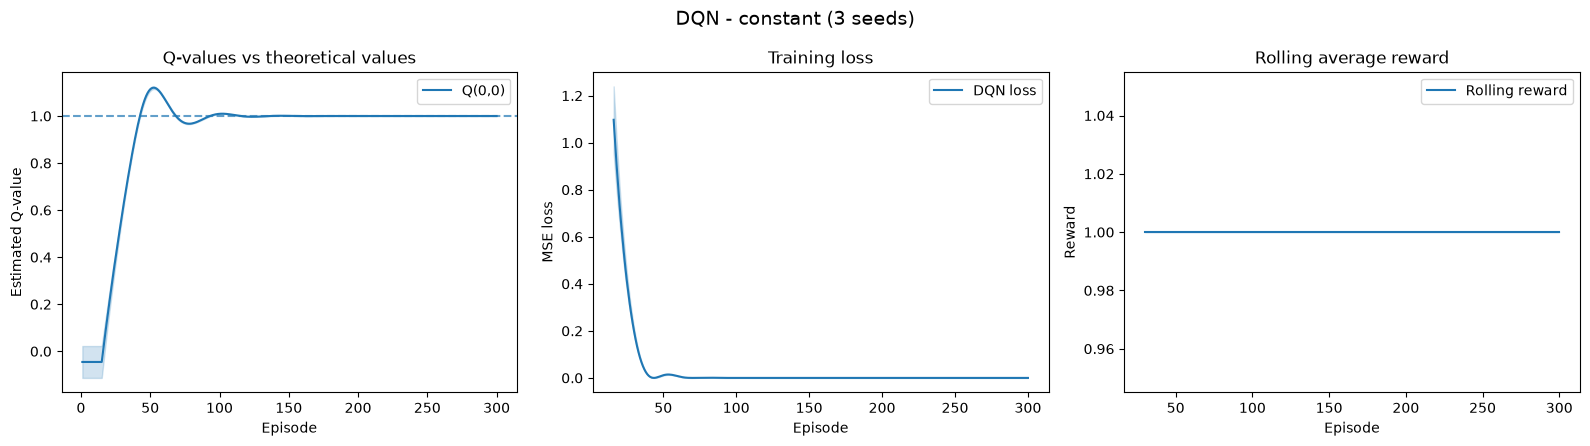

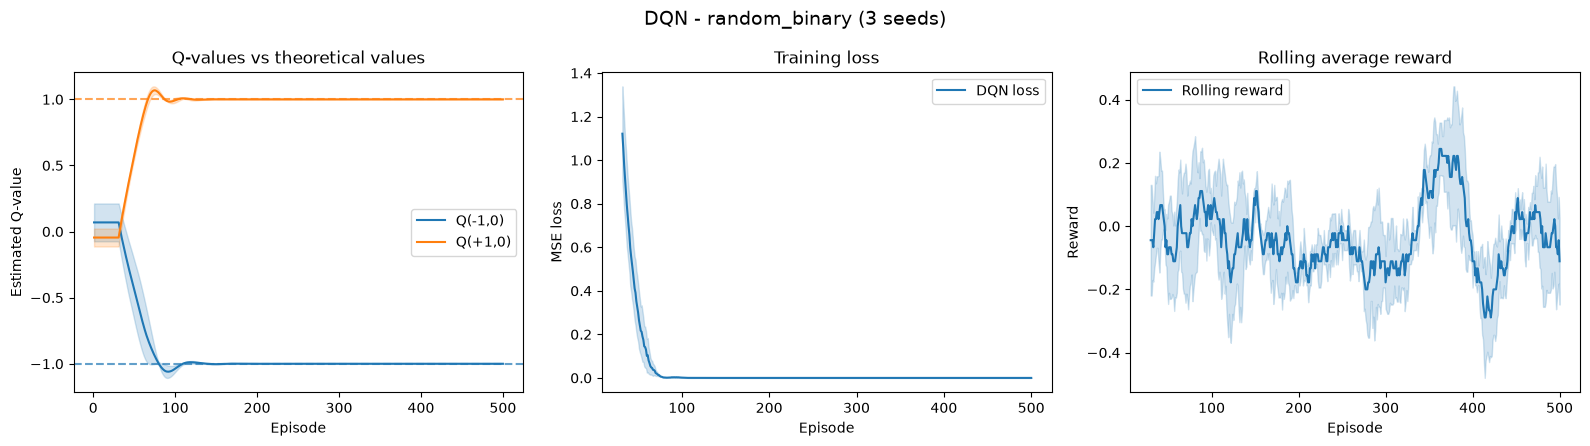

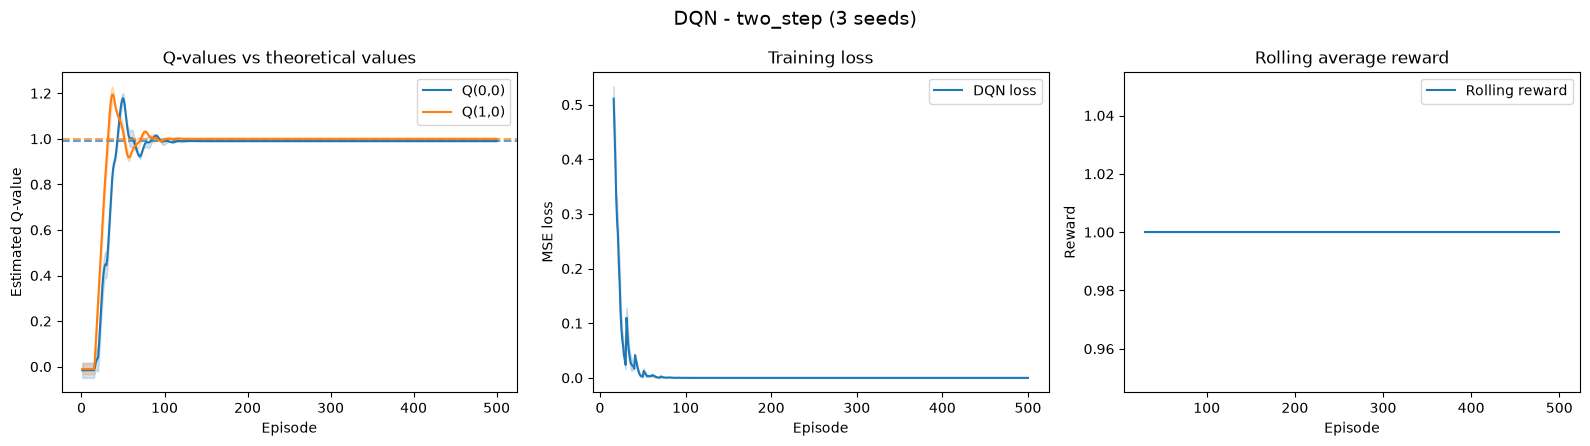

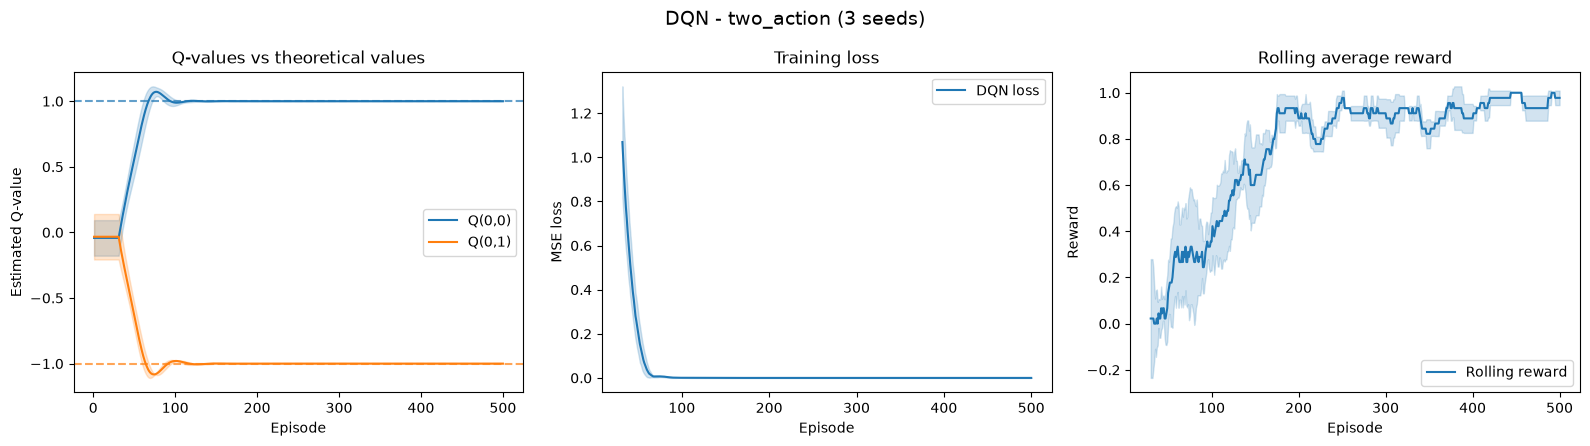

In [22]:
os.makedirs("results/figures", exist_ok=True)

seeds = [42, 123, 456]

# Estados, acciones y valores Q teóricos de cada entorno
theoretical_q = {
    "constant": [
        ("state_0", 0, 1.0, "Q(0,0)")
    ],
    "random_binary": [
        ("state_minus1", 0, -1.0, "Q(-1,0)"),
        ("state_plus1", 0, 1.0, "Q(+1,0)")
    ],
    "two_step": [
        ("state_0", 0, 0.99, "Q(0,0)"),
        ("state_1", 0, 1.0, "Q(1,0)")
    ],
    "two_action": [
        ("state_0", 0, 1.0, "Q(0,0)"),
        ("state_0", 1, -1.0, "Q(0,1)")
    ]
}


def plot_mean_std(ax, x, runs, label):
    mean = np.mean(runs, axis=0)
    std = np.std(runs, axis=0)

    line, = ax.plot(x, mean, label=label)

    ax.fill_between(
        x,
        mean - std,
        mean + std,
        color=line.get_color(),
        alpha=0.2
    )

    return line


for env_name, q_specs in theoretical_q.items():

    # Cargar las tres corridas desde los archivos
    histories = [
        np.load(
            f"results/experiments/{env_name}_seed{seed}.npz"
        )
        for seed in seeds
    ]

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

    ax_q, ax_loss, ax_reward = axes

    # 1. Evolución de Q-values
    for state_name, action, target, label in q_specs:

        q_runs = np.stack([
            h[f"q_{state_name}"][:, action]
            for h in histories
        ])

        episodes = np.arange(1, q_runs.shape[1] + 1)

        line = plot_mean_std(
            ax_q,
            episodes,
            q_runs,
            label
        )

        ax_q.axhline(
            target,
            color=line.get_color(),
            linestyle="--",
            alpha=0.7
        )

    ax_q.set_title("Q-values vs theoretical values")
    ax_q.set_xlabel("Episode")
    ax_q.set_ylabel("Estimated Q-value")
    ax_q.legend()

    # 2. Evolución de loss
    loss_runs = np.stack([
        h["episode_losses"]
        for h in histories
    ])

    # Los primeros episodios no tienen loss
    # porque el replay buffer todavía se está llenando.
    valid = np.all(np.isfinite(loss_runs), axis=0)

    episodes_loss = np.arange(
        1, loss_runs.shape[1] + 1
    )[valid]

    plot_mean_std(
        ax_loss,
        episodes_loss,
        loss_runs[:, valid],
        "DQN loss"
    )

    ax_loss.set_title("Training loss")
    ax_loss.set_xlabel("Episode")
    ax_loss.set_ylabel("MSE loss")
    ax_loss.legend()

    # 3. Recompensa media móvil
    window = 30
    kernel = np.ones(window) / window

    reward_runs = np.stack([
        np.convolve(
            h["rewards"],
            kernel,
            mode="valid"
        )
        for h in histories
    ])

    episodes_reward = np.arange(
        window,
        window + reward_runs.shape[1]
    )

    plot_mean_std(
        ax_reward,
        episodes_reward,
        reward_runs,
        "Rolling reward"
    )

    ax_reward.set_title("Rolling average reward")
    ax_reward.set_xlabel("Episode")
    ax_reward.set_ylabel("Reward")
    ax_reward.legend()

    # Guardar figura
    fig.suptitle(
        f"DQN - {env_name} (3 seeds)",
        fontsize=14
    )

    plt.tight_layout()

    plt.savefig(
        f"results/figures/{env_name}_dqn.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    for h in histories:
        h.close()

### CartPole-v1

In [23]:
cartpole_env = gym.make("CartPole-v1")

print("Observation space:", cartpole_env.observation_space)
print("Action space:", cartpole_env.action_space)
print("Reward threshold:", cartpole_env.spec.reward_threshold)

cartpole_policy, cartpole_history = train_dqn(
    cartpole_env,
    num_episodes=500,
    capacity=10000,
    batch_size=64,
    gamma=0.99,
    lr=1e-3,
    epsilon_max=1.0,
    epsilon_min=0.05,
    epsilon_decay=0.005,
    target_update_freq=500,
    seed=42,
)

print(
    "Mean reward (last 100 episodes):",
    np.mean(cartpole_history["rewards"][-100:])
)

print(
    "Best episode reward:",
    np.max(cartpole_history["rewards"])
)

print(
    "Training time:",
    cartpole_history["wall_time"]
)

cartpole_env.close()

Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Action space: Discrete(2)
Reward threshold: 475.0
Mean reward (last 100 episodes): 155.05
Best episode reward: 500.0
Training time: 51.01246219998575


In [24]:
cartpole_eval_env = gym.make("CartPole-v1")

cartpole_eval = evaluate_dqn(
    cartpole_eval_env,
    cartpole_policy,
    num_episodes=100,
    epsilon=0.0,
    seed=1234
)

print(
    "Greedy evaluation mean reward:",
    cartpole_eval["mean_reward"]
)

print(
    "Best evaluation reward:",
    np.max(cartpole_eval["rewards"])
)

print(
    "Worst evaluation reward:",
    np.min(cartpole_eval["rewards"])
)

cartpole_eval_env.close()

Greedy evaluation mean reward: 485.07
Best evaluation reward: 500.0
Worst evaluation reward: 290.0


In [25]:
torch.save(
    cartpole_policy.state_dict(),
    "results/weights/cartpole_seed42.pt"
)

np.savez(
    "results/experiments/cartpole_seed42.npz",
    rewards=cartpole_history["rewards"],
    lengths=cartpole_history["lengths"],
    epsilons=cartpole_history["epsilons"],
    episode_losses=cartpole_history["episode_losses"],
    losses=cartpole_history["losses"],
    loss_steps=cartpole_history["loss_steps"],
    episode_times=cartpole_history["episode_times"],
    wall_time=cartpole_history["wall_time"],
    evaluation_rewards=cartpole_eval["rewards"]
)

print("CartPole results saved.")

CartPole results saved.


### CartPole - Múltiples semillas

In [26]:
os.makedirs("results/experiments", exist_ok=True)
os.makedirs("results/weights", exist_ok=True)

# La semilla 42 ya fue entrenada y guardada
seeds = [123, 456]

for seed in seeds:
    print(f"\n--- CartPole | Seed {seed} ---")

    train_env = gym.make("CartPole-v1")

    policy, history = train_dqn(
        train_env,
        num_episodes=500,
        capacity=10000,
        batch_size=64,
        gamma=0.99,
        lr=1e-3,
        epsilon_max=1.0,
        epsilon_min=0.05,
        epsilon_decay=0.005,
        target_update_freq=500,
        seed=seed,
    )

    train_env.close()

    # Evaluación sin exploración
    eval_env = gym.make("CartPole-v1")

    evaluation = evaluate_dqn(
        eval_env,
        policy,
        num_episodes=100,
        epsilon=0.0,
        seed=1234
    )

    eval_env.close()

    # Guardar pesos
    torch.save(
        policy.state_dict(),
        f"results/weights/cartpole_seed{seed}.pt"
    )

    # Guardar historial
    np.savez(
        f"results/experiments/cartpole_seed{seed}.npz",
        rewards=history["rewards"],
        lengths=history["lengths"],
        epsilons=history["epsilons"],
        episode_losses=history["episode_losses"],
        losses=history["losses"],
        loss_steps=history["loss_steps"],
        episode_times=history["episode_times"],
        wall_time=history["wall_time"],
        evaluation_rewards=evaluation["rewards"]
    )

    print(
        "Mean training reward (last 100):",
        np.mean(history["rewards"][-100:])
    )

    print(
        "Mean greedy evaluation reward:",
        evaluation["mean_reward"]
    )

    print(
        "Best training episode:",
        np.max(history["rewards"])
    )

    print(
        "Training time:",
        history["wall_time"]
    )

print("\nBoth additional seeds completed.")


--- CartPole | Seed 123 ---
Mean training reward (last 100): 105.58
Mean greedy evaluation reward: 115.54
Best training episode: 422.0
Training time: 42.607078900007764

--- CartPole | Seed 456 ---
Mean training reward (last 100): 86.58
Mean greedy evaluation reward: 101.73
Best training episode: 408.0
Training time: 31.317908500001067

Both additional seeds completed.


### CartPole - Análisis de convergencia

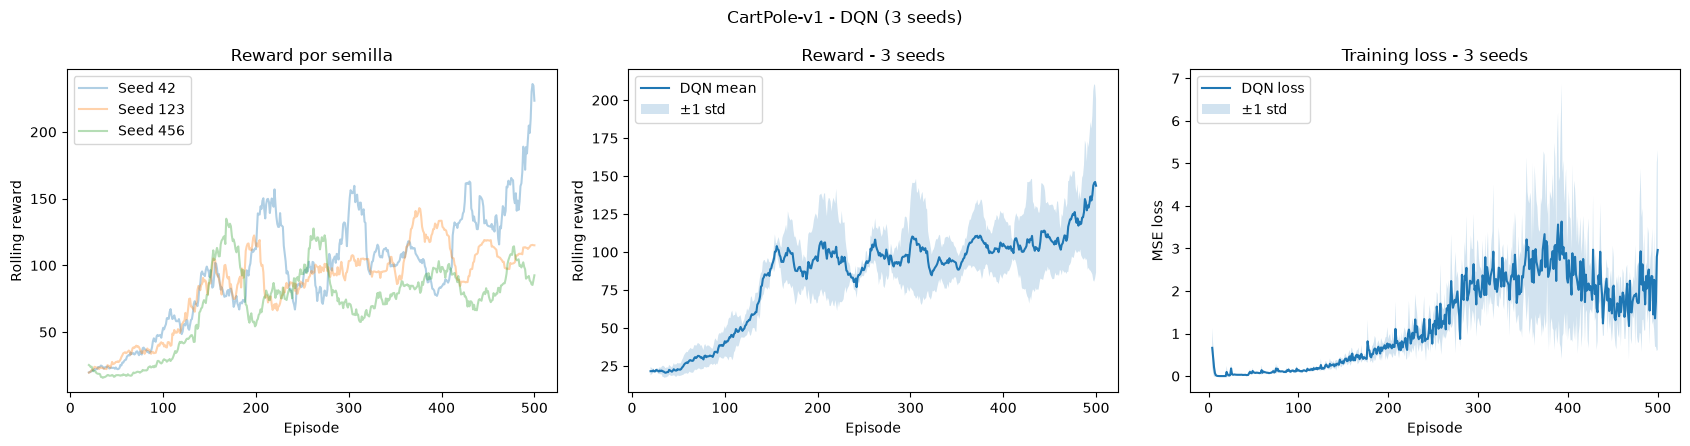

In [27]:
seeds = [42, 123, 456]

histories = [
    np.load(f"results/experiments/cartpole_seed{seed}.npz")
    for seed in seeds
]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# 1. Rewards de las tres semillas
window = 20
kernel = np.ones(window) / window

reward_runs = np.array([
    np.convolve(h["rewards"], kernel, mode="valid")
    for h in histories
])

episodes = np.arange(window, 501)

for i, seed in enumerate(seeds):
    axes[0].plot(
        episodes,
        reward_runs[i],
        alpha=0.35,
        label=f"Seed {seed}"
    )

axes[0].set_title("Reward por semilla")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Rolling reward")
axes[0].legend()


# 2. Reward promedio ± desviación estándar
mean_reward = reward_runs.mean(axis=0)
std_reward = reward_runs.std(axis=0)

axes[1].plot(
    episodes,
    mean_reward,
    label="DQN mean"
)

axes[1].fill_between(
    episodes,
    mean_reward - std_reward,
    mean_reward + std_reward,
    alpha=0.2,
    label="±1 std"
)

axes[1].set_title("Reward - 3 seeds")
axes[1].set_xlabel("Episode")
axes[1].set_ylabel("Rolling reward")
axes[1].legend()


# 3. Loss promedio ± desviación estándar
loss_runs = np.array([
    h["episode_losses"]
    for h in histories
])

valid = np.all(np.isfinite(loss_runs), axis=0)

loss_mean = loss_runs[:, valid].mean(axis=0)
loss_std = loss_runs[:, valid].std(axis=0)

loss_episodes = np.arange(1, 501)[valid]

axes[2].plot(
    loss_episodes,
    loss_mean,
    label="DQN loss"
)

axes[2].fill_between(
    loss_episodes,
    loss_mean - loss_std,
    loss_mean + loss_std,
    alpha=0.2,
    label="±1 std"
)

axes[2].set_title("Training loss - 3 seeds")
axes[2].set_xlabel("Episode")
axes[2].set_ylabel("MSE loss")
axes[2].legend()

fig.suptitle("CartPole-v1 - DQN (3 seeds)")
plt.tight_layout()

plt.savefig(
    "results/figures/cartpole_dqn_initial.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

for h in histories:
    h.close()

### CartPole - Experimento 2

In [28]:
seeds = [42, 123, 456]

tuned_results = []

for seed in seeds:

    print(f"\n--- CartPole Tuned | Seed {seed} ---")

    train_env = gym.make("CartPole-v1")

    policy, history = train_dqn(
        train_env,
        num_episodes=800,
        capacity=10000,
        batch_size=64,
        gamma=0.99,
        lr=5e-4,
        epsilon_max=1.0,
        epsilon_min=0.05,
        epsilon_decay=0.007,
        target_update_freq=500,
        seed=seed,
    )

    train_env.close()

    eval_env = gym.make("CartPole-v1")

    evaluation = evaluate_dqn(
        eval_env,
        policy,
        num_episodes=100,
        epsilon=0.0,
        seed=1234
    )

    eval_env.close()

    torch.save(
        policy.state_dict(),
        f"results/weights/cartpole_tuned_seed{seed}.pt"
    )

    np.savez(
        f"results/experiments/cartpole_tuned_seed{seed}.npz",
        rewards=history["rewards"],
        lengths=history["lengths"],
        epsilons=history["epsilons"],
        episode_losses=history["episode_losses"],
        losses=history["losses"],
        loss_steps=history["loss_steps"],
        episode_times=history["episode_times"],
        wall_time=history["wall_time"],
        evaluation_rewards=evaluation["rewards"]
    )

    tuned_results.append(evaluation["mean_reward"])

    print(
        "Mean training reward (last 100):",
        np.mean(history["rewards"][-100:])
    )

    print(
        "Mean greedy evaluation reward:",
        evaluation["mean_reward"]
    )

    print(
        "Best training episode:",
        np.max(history["rewards"])
    )

    print(
        "Training time:",
        history["wall_time"]
    )

print("\n--- Final comparison ---")

original_scores = [485.07, 115.54, 101.73]

print("Original evaluation scores:", original_scores)
print("Tuned evaluation scores:", tuned_results)

print("Original mean:", np.mean(original_scores))
print("Tuned mean:", np.mean(tuned_results))


--- CartPole Tuned | Seed 42 ---
Mean training reward (last 100): 393.95
Mean greedy evaluation reward: 500.0
Best training episode: 500.0
Training time: 158.8760864000069

--- CartPole Tuned | Seed 123 ---
Mean training reward (last 100): 384.69
Mean greedy evaluation reward: 500.0
Best training episode: 500.0
Training time: 181.754297699983

--- CartPole Tuned | Seed 456 ---
Mean training reward (last 100): 339.41
Mean greedy evaluation reward: 216.78
Best training episode: 500.0
Training time: 146.31762970000273

--- Final comparison ---
Original evaluation scores: [485.07, 115.54, 101.73]
Tuned evaluation scores: [500.0, 500.0, 216.78]
Original mean: 234.11333333333334
Tuned mean: 405.5933333333333


### CartPole - Comparación de experimentos

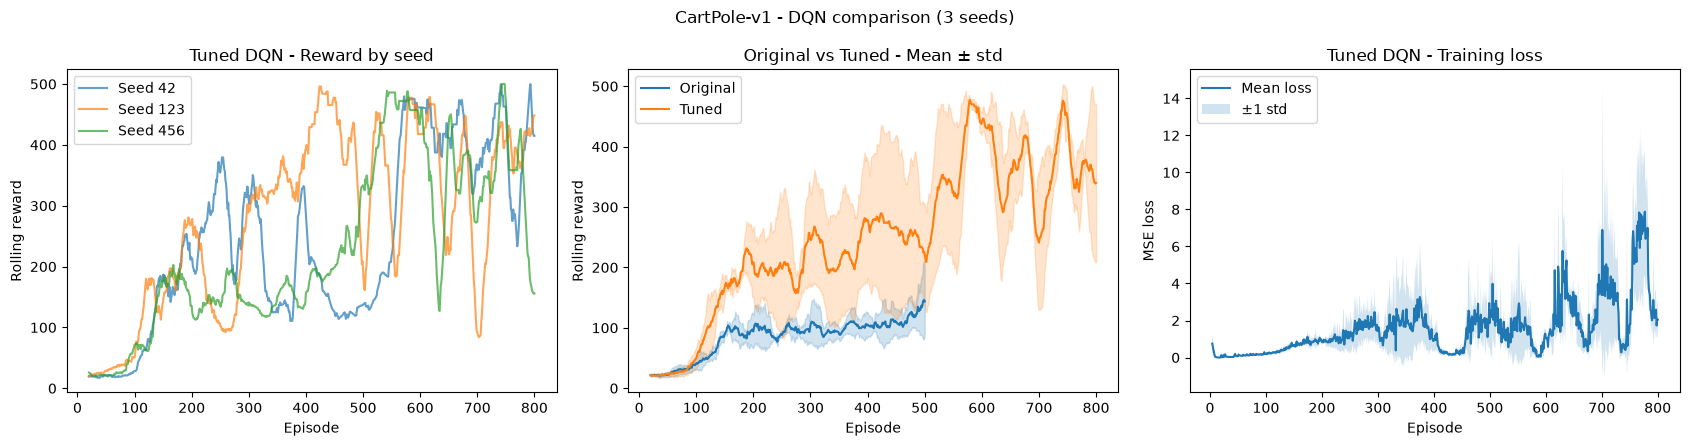

In [29]:
seeds = [42, 123, 456]
window = 20
kernel = np.ones(window) / window


def load_cartpole_runs(prefix):
    runs = []

    for seed in seeds:
        with np.load(
            f"results/experiments/{prefix}_seed{seed}.npz"
        ) as data:
            runs.append({
                "rewards": data["rewards"].copy(),
                "losses": data["episode_losses"].copy(),
                "evaluation": data["evaluation_rewards"].copy()
            })

    return runs


original_runs = load_cartpole_runs("cartpole")
tuned_runs = load_cartpole_runs("cartpole_tuned")


def rolling_rewards(runs):
    return np.stack([
        np.convolve(
            run["rewards"],
            kernel,
            mode="valid"
        )
        for run in runs
    ])


original_rewards = rolling_rewards(original_runs)
tuned_rewards = rolling_rewards(tuned_runs)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))


# 1. Recompensa por semilla (experimento ajustado)
episodes_tuned = np.arange(window, 801)

for i, seed in enumerate(seeds):
    axes[0].plot(
        episodes_tuned,
        tuned_rewards[i],
        alpha=0.7,
        label=f"Seed {seed}"
    )

axes[0].set_title("Tuned DQN - Reward by seed")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Rolling reward")
axes[0].legend()


# 2. Comparación de promedios entre configuraciones
for label, runs in [
    ("Original", original_rewards),
    ("Tuned", tuned_rewards)
]:
    episodes = np.arange(
        window,
        window + runs.shape[1]
    )

    mean = runs.mean(axis=0)
    std = runs.std(axis=0)

    line, = axes[1].plot(
        episodes,
        mean,
        label=label
    )

    axes[1].fill_between(
        episodes,
        mean - std,
        mean + std,
        alpha=0.2,
        color=line.get_color()
    )

axes[1].set_title("Original vs Tuned - Mean ± std")
axes[1].set_xlabel("Episode")
axes[1].set_ylabel("Rolling reward")
axes[1].legend()


# 3. Loss del experimento ajustado
loss_runs = np.stack([
    run["losses"]
    for run in tuned_runs
])

valid = np.all(np.isfinite(loss_runs), axis=0)

mean_loss = loss_runs[:, valid].mean(axis=0)
std_loss = loss_runs[:, valid].std(axis=0)

episodes_loss = np.arange(1, 801)[valid]

axes[2].plot(
    episodes_loss,
    mean_loss,
    label="Mean loss"
)

axes[2].fill_between(
    episodes_loss,
    mean_loss - std_loss,
    mean_loss + std_loss,
    alpha=0.2,
    label="±1 std"
)

axes[2].set_title("Tuned DQN - Training loss")
axes[2].set_xlabel("Episode")
axes[2].set_ylabel("MSE loss")
axes[2].legend()

fig.suptitle("CartPole-v1 - DQN comparison (3 seeds)")
plt.tight_layout()

plt.savefig(
    "results/figures/cartpole_dqn_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

### MountainCar-v0 - Baseline DQN

In [30]:
mc_env = gym.make("MountainCar-v0")

print("Observation space:", mc_env.observation_space)
print("Action space:", mc_env.action_space)
print("Reward threshold:", mc_env.spec.reward_threshold)

mc_policy, mc_history = train_dqn(
    mc_env,
    num_episodes=400,
    capacity=20000,
    batch_size=64,
    gamma=0.99,
    lr=5e-4,
    epsilon_max=1.0,
    epsilon_min=0.05,
    epsilon_decay=0.005,
    target_update_freq=500,
    seed=42
)

print(
    "Mean reward (last 100 episodes):",
    np.mean(mc_history["rewards"][-100:])
)

print(
    "Best training reward:",
    np.max(mc_history["rewards"])
)

print(
    "Training time:",
    mc_history["wall_time"]
)

mc_env.close()

Observation space: Box([-1.2  -0.07], [0.6  0.07], (2,), float32)
Action space: Discrete(3)
Reward threshold: -110.0
Mean reward (last 100 episodes): -199.61
Best training reward: -178.0
Training time: 64.44682000001194


In [31]:
mc_eval_env = gym.make("MountainCar-v0")

mc_evaluation = evaluate_dqn(
    mc_eval_env,
    mc_policy,
    num_episodes=100,
    epsilon=0.0,
    seed=1234
)

print(
    "Mean greedy evaluation reward:",
    mc_evaluation["mean_reward"]
)

print(
    "Best evaluation reward:",
    np.max(mc_evaluation["rewards"])
)

print(
    "Episodes with reward > -200:",
    np.sum(mc_evaluation["rewards"] > -200),
    "/ 100"
)

mc_eval_env.close()

Mean greedy evaluation reward: -198.23
Best evaluation reward: -192.0
Episodes with reward > -200: 25 / 100


In [32]:
torch.save(
    mc_policy.state_dict(),
    "results/weights/mountaincar_baseline_seed42.pt"
)

np.savez(
    "results/experiments/mountaincar_baseline_seed42.npz",
    rewards=mc_history["rewards"],
    lengths=mc_history["lengths"],
    epsilons=mc_history["epsilons"],
    episode_losses=mc_history["episode_losses"],
    losses=mc_history["losses"],
    loss_steps=mc_history["loss_steps"],
    episode_times=mc_history["episode_times"],
    wall_time=mc_history["wall_time"],
    evaluation_rewards=mc_evaluation["rewards"]
)

print("MountainCar baseline saved.")

MountainCar baseline saved.


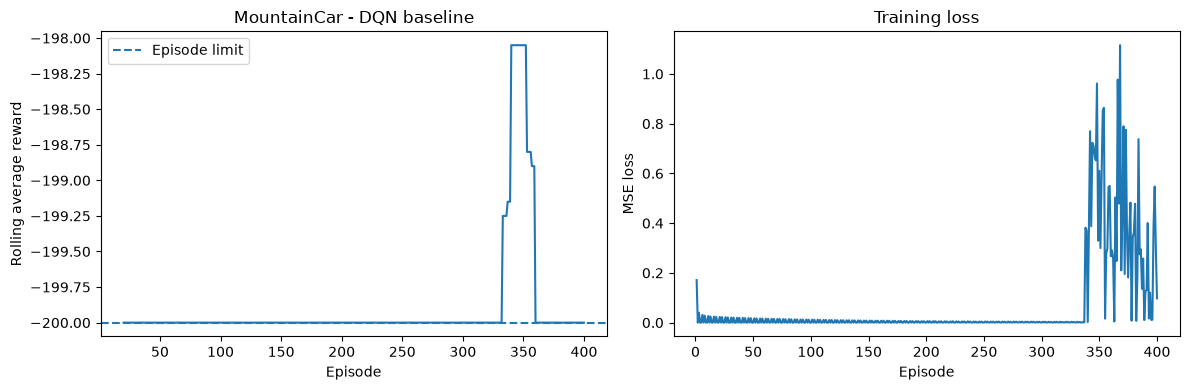

In [33]:
window = 20

moving_average = np.convolve(
    mc_history["rewards"],
    np.ones(window) / window,
    mode="valid"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    np.arange(window, 401),
    moving_average
)

axes[0].set_title("MountainCar - DQN baseline")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Rolling average reward")
axes[0].axhline(-200, linestyle="--", label="Episode limit")
axes[0].legend()

losses = mc_history["episode_losses"]
valid = np.isfinite(losses)

axes[1].plot(
    np.arange(1, 401)[valid],
    losses[valid]
)

axes[1].set_title("Training loss")
axes[1].set_xlabel("Episode")
axes[1].set_ylabel("MSE loss")

plt.tight_layout()
plt.show()

### MountainCar-v0 - Normalized observations

In [34]:
from utils import NormalizeMountainCarObservation

mc_norm_env = NormalizeMountainCarObservation(
    gym.make("MountainCar-v0")
)

obs, _ = mc_norm_env.reset(seed=42)

print("Normalized observation:", obs)
print("Observation space:", mc_norm_env.observation_space)

mc_norm_env.close()

Normalized observation: [-0.16134308  0.        ]
Observation space: Box(-1.0, 1.0, (2,), float32)


In [35]:
mc_norm_env = NormalizeMountainCarObservation(
    gym.make("MountainCar-v0")
)

mc_norm_policy, mc_norm_history = train_dqn(
    mc_norm_env,
    num_episodes=400,
    capacity=20000,
    batch_size=64,
    gamma=0.99,
    lr=5e-4,
    epsilon_max=1.0,
    epsilon_min=0.05,
    epsilon_decay=0.005,
    target_update_freq=500,
    seed=42
)

mc_norm_env.close()

mc_norm_eval_env = NormalizeMountainCarObservation(
    gym.make("MountainCar-v0")
)

mc_norm_evaluation = evaluate_dqn(
    mc_norm_eval_env,
    mc_norm_policy,
    num_episodes=100,
    epsilon=0.0,
    seed=1234
)

mc_norm_eval_env.close()

print(
    "Mean training reward (last 100):",
    np.mean(mc_norm_history["rewards"][-100:])
)

print(
    "Best training reward:",
    np.max(mc_norm_history["rewards"])
)

print(
    "Mean greedy evaluation reward:",
    mc_norm_evaluation["mean_reward"]
)

print(
    "Episodes with reward > -200:",
    np.sum(mc_norm_evaluation["rewards"] > -200),
    "/ 100"
)

print(
    "Training time:",
    mc_norm_history["wall_time"]
)

Mean training reward (last 100): -198.47
Best training reward: -138.0
Mean greedy evaluation reward: -200.0
Episodes with reward > -200: 0 / 100
Training time: 75.58930079999845


In [36]:
torch.save(
    mc_norm_policy.state_dict(),
    "results/weights/mountaincar_normalized_seed42.pt"
)

np.savez(
    "results/experiments/mountaincar_normalized_seed42.npz",
    rewards=mc_norm_history["rewards"],
    lengths=mc_norm_history["lengths"],
    epsilons=mc_norm_history["epsilons"],
    episode_losses=mc_norm_history["episode_losses"],
    losses=mc_norm_history["losses"],
    loss_steps=mc_norm_history["loss_steps"],
    episode_times=mc_norm_history["episode_times"],
    wall_time=mc_norm_history["wall_time"],
    evaluation_rewards=mc_norm_evaluation["rewards"]
)

print("Normalized MountainCar experiment saved.")

Normalized MountainCar experiment saved.


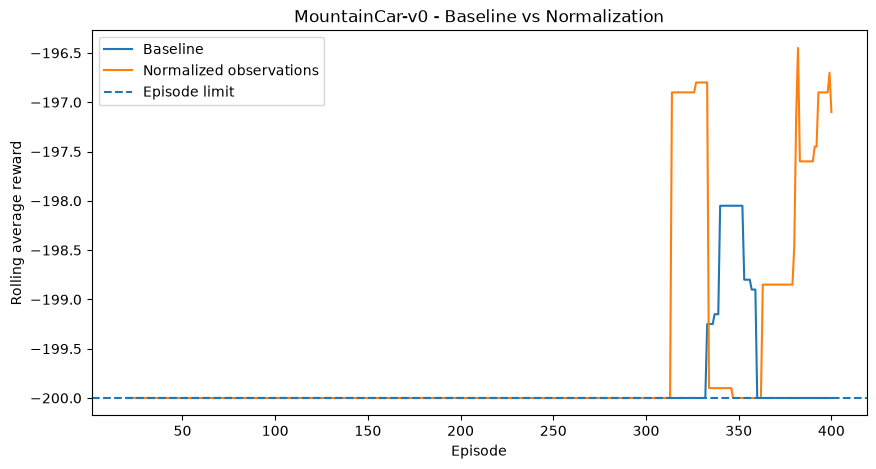

In [37]:
window = 20
kernel = np.ones(window) / window

baseline_rewards = np.convolve(
    mc_history["rewards"],
    kernel,
    mode="valid"
)

normalized_rewards = np.convolve(
    mc_norm_history["rewards"],
    kernel,
    mode="valid"
)

episodes = np.arange(window, 401)

plt.figure(figsize=(10, 5))

plt.plot(
    episodes,
    baseline_rewards,
    label="Baseline"
)

plt.plot(
    episodes,
    normalized_rewards,
    label="Normalized observations"
)

plt.axhline(
    -200,
    linestyle="--",
    label="Episode limit"
)

plt.xlabel("Episode")
plt.ylabel("Rolling average reward")
plt.title("MountainCar-v0 - Baseline vs Normalization")
plt.legend()
plt.show()